# 09 — Segmentation and how we see

**Segmentation and how we see.** A computational companion to the paper. This notebook makes the annotation → learning → overlay → reflection sequence executable.

**Claim.** A learned boundary depends on the annotation task. A segmentation output is a proposed partition; examining learned features and intervening on a model answers additional questions.

**Method.** Generate independent, two-channel synthetic images. Fit two small neural segmenters to identical training images and different boundary policies. Evaluate on images withheld from training, inspect hidden features, and perform input and hidden-unit interventions. NumPy implements the training; Matplotlib draws the results. No pretrained weights or additional packages beyond the project dependencies are needed.

**Human reflection.** Inspect the raw image before revealing its overlays. Record what changes in your interpretation. This is a guided exercise, not a measurement of reader behaviour or evidence that an overlay improves human accuracy.

**Scope.** These deliberately simple phantoms are not patient images or a physical MRI simulation. The networks have three trained affine layers, two tanh hidden layers, and fixed local input features. They are not a clinical segmentation architecture. A high synthetic Dice score establishes agreement with a chosen synthetic label policy, not clinical validity, semantic understanding, or human experience.

Run from a complete checkout with the environment described in the [README](../../README.md#run-the-notebooks). Choose **Restart Kernel and Run All Cells** to reproduce the computational results. For the reflection, execute cells individually and pause before the overlay cell. Training normally takes seconds on a CPU. Figures and a numerical summary are written only under ignored `.build/segmentation-reflection/`; existing manuscript figures are untouched.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

repo = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'code' / 'src').is_dir())
sys.path.insert(0, str(repo / 'code' / 'src'))
from brainsmodels.segmentation_reflection import (
    make_dataset, train, dice, gradient_error, channel_intervention, ablate_unit,
)

SEED = 7
THRESHOLD = 0.5  # Fixed before evaluation; not selected on held-out images.
OUTPUT = repo / '.build' / 'segmentation-reflection'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10})

def show_figure(fig, name):
    fig.savefig(OUTPUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Seed:', SEED)
print('NumPy:', np.__version__)
print('Outputs: .build/segmentation-reflection/')


Seed: 7
NumPy: 2.5.2
Outputs: .build/segmentation-reflection/


## 1. Define the image and the annotation task separately

Each image contains an elliptical core, a surrounding band, and an unrelated bright distractor in channel A. Channel B provides another designed signal. Geometry determines the two reference masks; the model receives only four features per pixel: intensities A and B and their fixed 3×3 local means. It receives no reference masks or coordinates as input.

The **core** policy marks the inner ellipse. The **inclusive** policy marks the core plus surrounding band. These stand for different task definitions, not two estimates of a known clinical truth. We know their construction because we designed the phantom.

The split is by whole image. All pixels from a held-out image stay out of training, including computation of feature normalization. Both fits use identical training images, initialization, optimization settings, and pixel-sampling sequences. Only the labels change.


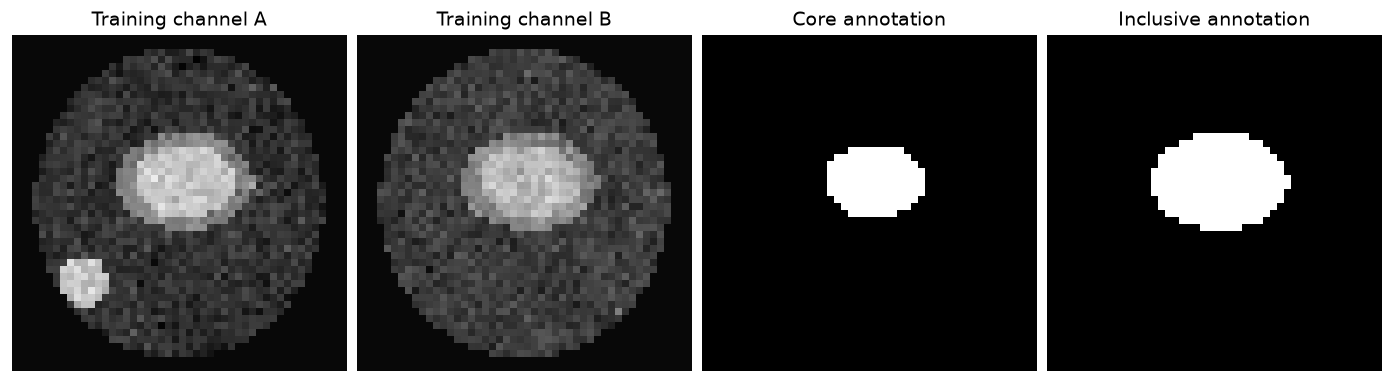

20 training images; 6 held-out images.


In [2]:
training = make_dataset(20, seed=SEED)
heldout = make_dataset(6, seed=2026)
assert not set(training.case_seeds) & set(heldout.case_seeds)
assert np.all(training.core <= training.inclusive)

case = 0  # Fixed example, not selected for a favourable result.
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), layout='constrained')
for ax, values, title in zip(axes,
        [training.images[0, ..., 0], training.images[0, ..., 1],
         training.core[0], training.inclusive[0]],
        ['Training channel A', 'Training channel B', 'Core annotation', 'Inclusive annotation']):
    ax.imshow(values, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
show_figure(fig, '01-training-and-annotation-policies')
print(f'{len(training.images)} training images; {len(heldout.images)} held-out images.')


## 2. Learn two segmenters

For each pixel the network computes $h_1=\tanh(xW_1+b_1)$, $h_2=\tanh(h_1W_2+b_2)$, and $p=\sigma(h_2W_3+b_3)$. The hidden widths are 16 and 8. Binary cross-entropy is minimized using Adam for 350 steps; there is no early stopping or held-out parameter selection. The shared implementation is in [segmentation_reflection.py](../src/brainsmodels/segmentation_reflection.py).

First check analytic backpropagation against central finite differences for **all 225 trainable parameters**. Then fit the two policies. The loss curves below use a fixed training-only monitoring sample.


Maximum gradient error: 1.25e-11


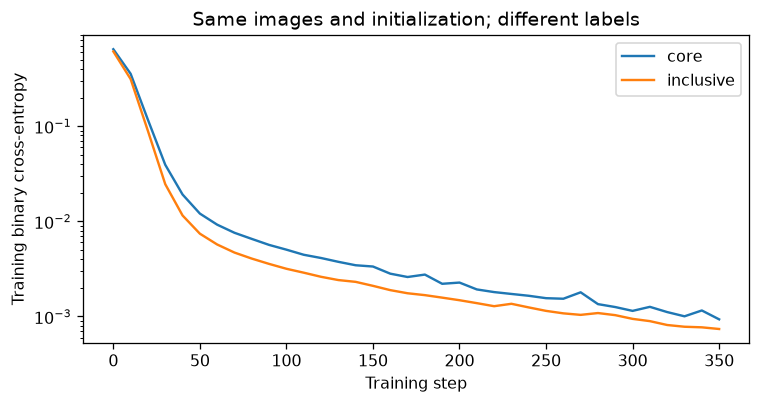

In [3]:
max_gradient_error = gradient_error()
assert max_gradient_error < 1e-7
print(f'Maximum gradient error: {max_gradient_error:.3g}')

models = {policy: train(training.images, getattr(training, policy), seed=SEED)
          for policy in ('core', 'inclusive')}
probabilities = {policy: model.predict(heldout.images) for policy, model in models.items()}
masks = {policy: probability >= THRESHOLD for policy, probability in probabilities.items()}

fig, ax = plt.subplots(figsize=(6.5, 3.4), layout='constrained')
for policy, model in models.items():
    ax.plot(np.arange(len(model.losses)) * 10, model.losses, label=policy)
    assert model.losses[-1] < model.losses[0]
ax.set(xlabel='Training step', ylabel='Training binary cross-entropy',
       title='Same images and initialization; different labels', yscale='log')
ax.legend()
show_figure(fig, '02-training-loss')


## 3. Evaluate against both policies

For predicted mask $P$ and reference mask $R$, Dice is $2|P\cap R|/(|P|+|R|)$. A pair of empty masks is defined to have score 1. Evaluate each model against **both** references, using a probability threshold of 0.5 fixed in advance. Report every held-out image as well as the means.

These phantoms are intentionally easy to separate. Good scores are expected by construction. Notice how the assessment changes when the reference policy changes: “agreement” has to name its reference.


In [4]:
print('                    Dice vs core     Dice vs inclusive')
score_table = {}
for policy in models:
    core_scores = dice(masks[policy], heldout.core)
    inclusive_scores = dice(masks[policy], heldout.inclusive)
    score_table[policy] = {'core': core_scores.tolist(), 'inclusive': inclusive_scores.tolist()}
    print(f'{policy:18s} {core_scores.mean():.3f}            {inclusive_scores.mean():.3f}')
    for i, (a, b) in enumerate(zip(core_scores, inclusive_scores)):
        print(f'  held-out case {i}:   {a:.3f}            {b:.3f}')
    own_scores = dice(masks[policy], getattr(heldout, policy))
    assert own_scores.mean() > 0.90

areas = {policy: mask.sum(axis=(1, 2)) for policy, mask in masks.items()}
assert np.all(areas['inclusive'] > areas['core'])
print('Predicted foreground pixels per image:')
for policy, area in areas.items():
    print(f'  {policy}: {area.tolist()}')


                    Dice vs core     Dice vs inclusive
core               1.000            0.709
  held-out case 0:   1.000            0.702
  held-out case 1:   1.000            0.710
  held-out case 2:   1.000            0.716
  held-out case 3:   1.000            0.718
  held-out case 4:   1.000            0.700
  held-out case 5:   1.000            0.707
inclusive          0.709            1.000
  held-out case 0:   0.702            1.000
  held-out case 1:   0.710            1.000
  held-out case 2:   0.716            1.000
  held-out case 3:   0.718            1.000
  held-out case 4:   0.700            1.000
  held-out case 5:   0.707            1.000
Predicted foreground pixels per image:
  core: [161, 131, 122, 140, 105, 118]
  inclusive: [298, 238, 219, 250, 195, 216]


## 4. Pause before revealing an overlay

Look at this **held-out** raw image first. In a separate note, describe which region you would investigate, what boundary seems defensible, and what you remain uncertain about. Do this before running the next cell after the raw-image display. This note is a personal reflection; the notebook does not collect or score it.


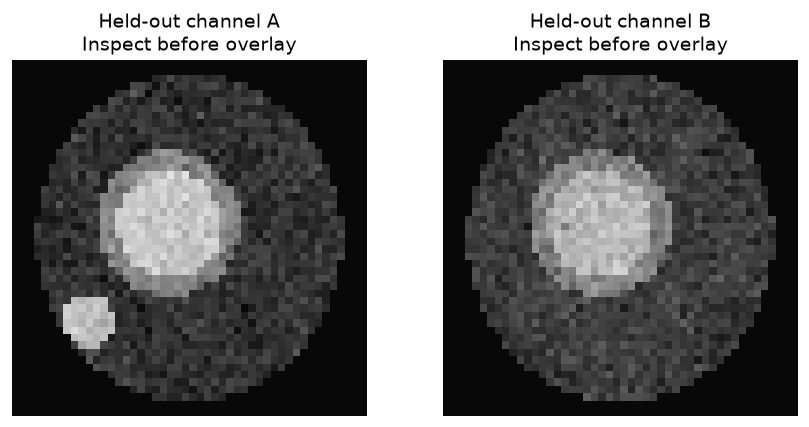

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6), layout='constrained')
for channel, ax in enumerate(axes):
    ax.imshow(heldout.images[case, ..., channel], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Held-out channel {"AB"[channel]}\nInspect before overlay')
    ax.axis('off')
show_figure(fig, '03-raw-before-overlay')


### Reveal: same image, two learned proposals

The raw intensities stay exactly the same in all three panels. Orange marks a model's thresholded foreground; its opacity is a display choice, not uncertainty. The rightmost panel shows where the predicted masks disagree.

After inspecting the overlay, return to the raw image. Did you attend to a region you had previously overlooked? Did either contour become your default boundary? What would distinguish useful guidance from anchoring on an incorrect proposal? Your response motivates a question about perception; it does not demonstrate a measured effect on clinicians.


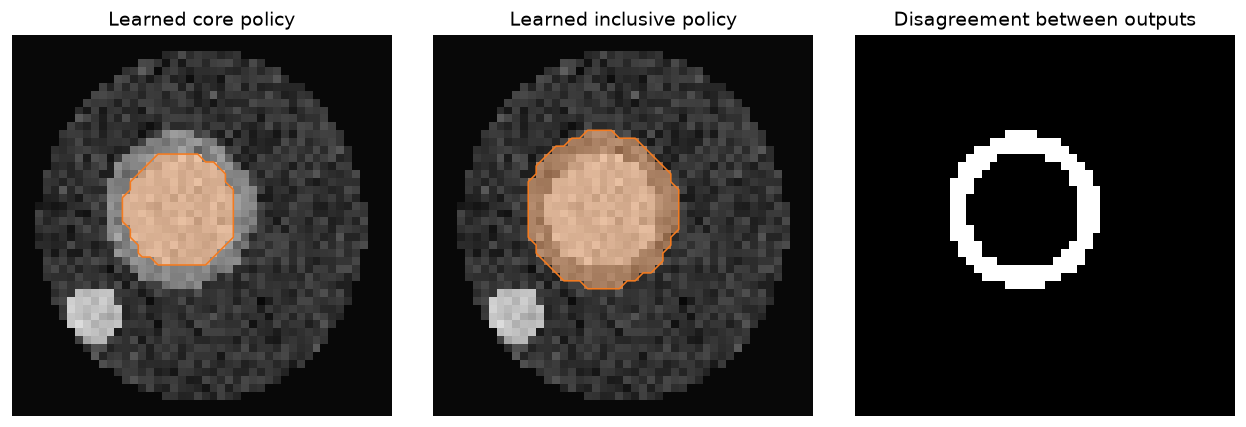

In [6]:
def draw_overlay(ax, image, mask, alpha=0.30):
    ax.imshow(image, cmap='gray', vmin=0, vmax=1)
    rgba = np.zeros((*mask.shape, 4))
    rgba[..., :3] = [1.0, 0.47, 0.08]
    rgba[..., 3] = alpha * mask
    ax.imshow(rgba)
    if mask.any() and not mask.all():
        ax.contour(mask.astype(float), levels=[0.5], colors=['#f47b20'], linewidths=1)
    ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), layout='constrained')
for ax, policy in zip(axes[:2], models):
    draw_overlay(ax, heldout.images[case, ..., 0], masks[policy][case])
    ax.set_title(f'Learned {policy} policy')
axes[2].imshow(masks['core'][case] ^ masks['inclusive'][case], cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Disagreement between outputs')
axes[2].axis('off')
show_figure(fig, '04-overlays-and-disagreement')


### Try changing only the display

Edit `POLICY`, `DISPLAY_ALPHA`, or `DISPLAY_THRESHOLD` below, then rerun this cell. Changing opacity changes presentation without changing probabilities. Changing the threshold changes the displayed mask without retraining the network. These are different interventions; neither is a measurement of subjective confidence. The main evaluation above retains its predeclared threshold.


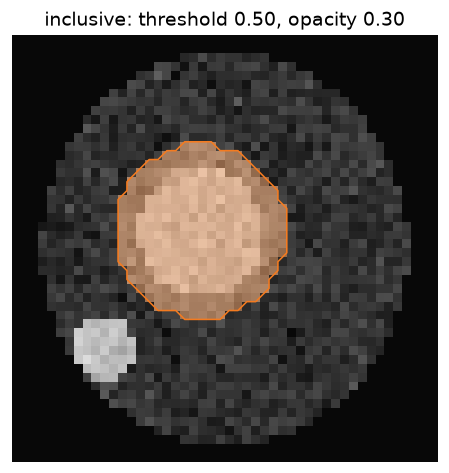

In [7]:
POLICY = 'inclusive'          # 'core' or 'inclusive'
DISPLAY_ALPHA = 0.30           # 0.0 to 1.0
DISPLAY_THRESHOLD = 0.50       # strictly between 0.0 and 1.0
assert POLICY in models
assert 0 <= DISPLAY_ALPHA <= 1 and 0 < DISPLAY_THRESHOLD < 1
fig, ax = plt.subplots(figsize=(4.5, 4.0), layout='constrained')
draw_overlay(ax, heldout.images[case, ..., 0],
             probabilities[POLICY][case] >= DISPLAY_THRESHOLD, DISPLAY_ALPHA)
ax.set_title(f'{POLICY}: threshold {DISPLAY_THRESHOLD:.2f}, opacity {DISPLAY_ALPHA:.2f}')
show_figure(fig, '05-display-experiment')


## 5. Change the input, preserve the specified target geometry

Replace one whole synthetic channel with the fixed value 0.24 and recompute all input features. The other channel and geometric reference masks remain unchanged. This is a deliberately strong, potentially out-of-distribution intervention, not a claim about realistic scanner variation. The replacement value is part of the question; try another value before generalizing the result.

Measure the mean absolute change in foreground probability and Dice against the matching reference across all held-out images. Both models can match their own annotations well while responding differently to a missing channel. Whole-channel replacement tests a model dependency under this intervention; it does not assign clinical meaning to a feature.


Model       Intervention   mean |delta p|    Dice vs own reference
core        replace A        0.0561           0.000
core        replace B        0.0560           0.000
inclusive   replace A        0.0045           0.988
inclusive   replace B        0.1023           0.000


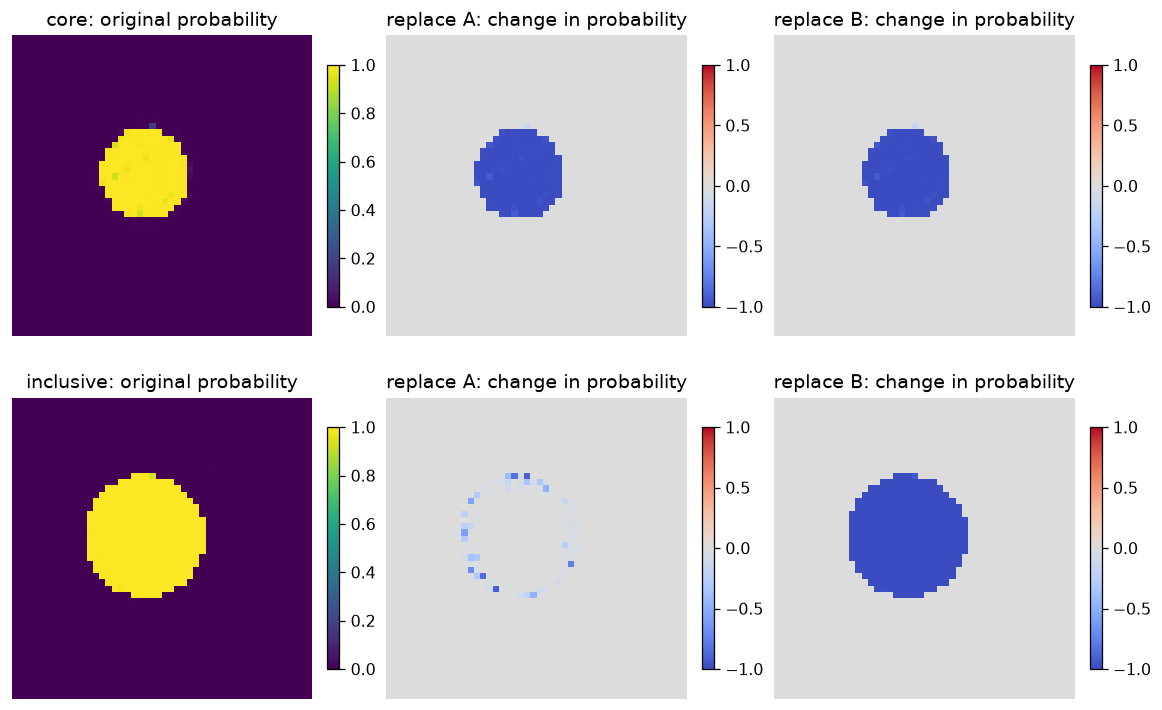

In [8]:
replacement_value = 0.24
interventions = {name: channel_intervention(heldout.images, channel, replacement_value)
                 for channel, name in enumerate(('replace A', 'replace B'))}
intervention_results = {}
print('Model       Intervention   mean |delta p|    Dice vs own reference')
for policy, model in models.items():
    intervention_results[policy] = {}
    for name, altered in interventions.items():
        probability = model.predict(altered)
        delta = float(np.mean(np.abs(probability - probabilities[policy])))
        overlap = float(dice(probability >= THRESHOLD, getattr(heldout, policy)).mean())
        intervention_results[policy][name] = {'mean_absolute_probability_change': delta,
                                             'mean_dice': overlap}
        print(f'{policy:11s} {name:14s} {delta:8.4f}           {overlap:.3f}')

fig, axes = plt.subplots(2, 3, figsize=(10, 6.3), layout='constrained')
for row, (policy, model) in enumerate(models.items()):
    base = probabilities[policy][case]
    image = axes[row, 0].imshow(base, cmap='viridis', vmin=0, vmax=1)
    axes[row, 0].set_title(f'{policy}: original probability')
    fig.colorbar(image, ax=axes[row, 0], shrink=0.7)
    for column, (name, altered) in enumerate(interventions.items(), 1):
        change = model.predict(altered)[case] - base
        image = axes[row, column].imshow(change, cmap='coolwarm', vmin=-1, vmax=1)
        axes[row, column].set_title(f'{name}: change in probability')
        fig.colorbar(image, ax=axes[row, column], shrink=0.7)
    for ax in axes[row]:
        ax.axis('off')
show_figure(fig, '06-channel-interventions')


## 6. Inspect a representation; then intervene on it

A mask is an output. The next display instead exposes learned second-hidden-layer activations of the **inclusive** model on the unmodified image. Four of its eight units are shown, ordered by absolute output weight for a legible display. This ordering is not a validated ranking of feature importance. All maps use the same tanh scale, −1 to 1.

Then set each of the eight hidden units to zero in turn, retaining all weights, and measure the probability change over the held-out images. Also erase the entire hidden layer. A colourful activation alone is not a semantic label; a zero-replacement ablation gives an effect for that intervention and baseline. A small single-unit effect does not by itself establish redundancy or irrelevance.


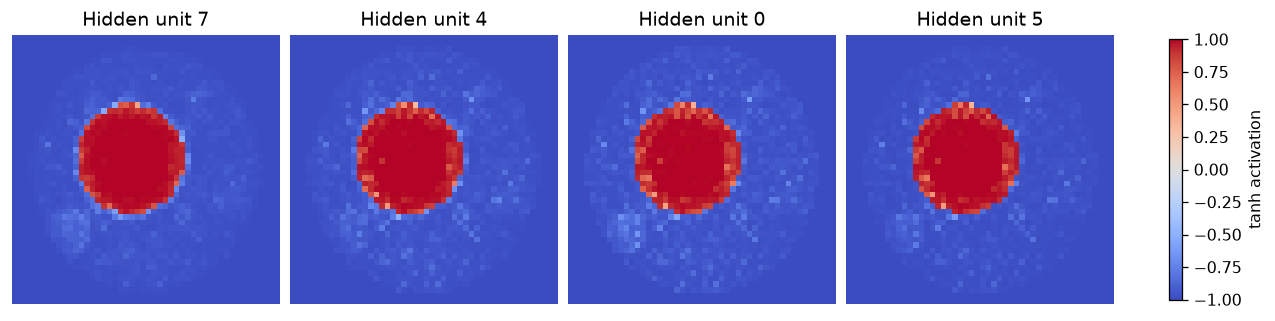

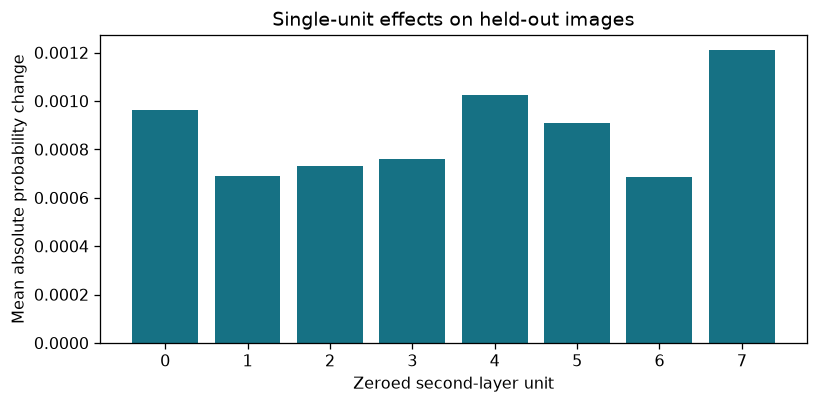

Single-unit effects: [0.000962 0.000692 0.000733 0.000762 0.001026 0.00091  0.000687 0.001212]
Erasing the whole hidden layer: mean |delta p| = 0.4374
Remaining constant probability: 0.42201429235643223


In [9]:
model = models['inclusive']
base, hidden = model.inspect(heldout.images)
shown_units = np.argsort(np.abs(model.parameters['w3'][:, 0]))[-4:][::-1]
fig, axes = plt.subplots(1, 4, figsize=(11, 3.1), layout='constrained')
for ax, unit in zip(axes, shown_units):
    image = ax.imshow(hidden[case, ..., unit], cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_title(f'Hidden unit {unit}')
    ax.axis('off')
fig.colorbar(image, ax=list(axes), shrink=0.75, label='tanh activation')
show_figure(fig, '07-learned-hidden-features')

unit_effects = np.array([np.abs(ablate_unit(model, heldout.images, unit) - base).mean()
                         for unit in range(8)])
# With all second-layer activations zero, only the learned output bias remains.
from brainsmodels.segmentation_reflection import sigmoid
all_erased = np.full_like(base, float(sigmoid(model.parameters['b3'])[0]))
all_erased_effect = float(np.abs(all_erased - base).mean())
fig, ax = plt.subplots(figsize=(7, 3.4), layout='constrained')
ax.bar(np.arange(8), unit_effects, color='#167184')
ax.set(xlabel='Zeroed second-layer unit', ylabel='Mean absolute probability change',
       title='Single-unit effects on held-out images')
show_figure(fig, '08-hidden-unit-interventions')
print('Single-unit effects:', np.round(unit_effects, 6))
print(f'Erasing the whole hidden layer: mean |delta p| = {all_erased_effect:.4f}')
print('Remaining constant probability:', float(all_erased[0, 0, 0]))


### Same output, relabelled internal units

Permute the second-layer units **and** the corresponding output weights together. This is an exact change of parameterization: the feature maps acquire different unit indices while the output stays the same, within floating-point precision. It is a concrete reason to avoid inferring a unique explanation from the appearance or number of a hidden unit.

This elementary inspection explores learned features. It is **not** Network Dissection: [Bau et al. (2017)](https://arxiv.org/abs/1704.05796) quantify alignment with annotated semantic concepts, a further evaluation not implemented here.


In [10]:
from brainsmodels.segmentation_reflection import PixelNetwork
permutation = np.arange(8)[::-1]
permuted_parameters = {key: value.copy() for key, value in model.parameters.items()}
permuted_parameters['w2'] = permuted_parameters['w2'][:, permutation]
permuted_parameters['b2'] = permuted_parameters['b2'][permutation]
permuted_parameters['w3'] = permuted_parameters['w3'][permutation, :]
permuted_model = PixelNetwork(permuted_parameters, model.mean, model.scale, model.losses)
permuted_probability, permuted_hidden = permuted_model.inspect(heldout.images)
assert np.allclose(permuted_probability, base, atol=1e-12, rtol=0)
assert np.allclose(permuted_hidden, hidden[..., permutation], atol=1e-12, rtol=0)
print('Largest output change after coordinated permutation:',
      float(np.max(np.abs(permuted_probability - base))))


Largest output change after coordinated permutation: 1.1102230246251565e-16


## 7. Return to the interpretation questions

| Interpretation question | What this notebook supplies | What remains open |
|---|---|---|
| How do our annotations shape the model? | Matched fits with two policies produce different boundaries. | Whether either policy is appropriate for a clinical task. |
| Can an overlay reshape how we see? | Raw-first viewing, two overlays, disagreement and opacity experiments. | A measured effect on human attention, accuracy or confidence. |
| What has the model learned? | Hidden activations, channel interventions and hidden-unit ablations. | A unique semantic explanation or evidence of understanding. |
| What does agreeing on a boundary tell us? | Dice explicitly names the reference policy and threshold. | Agreement alone does not settle the meaning of the region. |

**Questions for reflection**

1. If both models have high Dice against their own labels, what additional evidence would justify preferring one boundary? Who should define the target?
2. Did the overlay make a boundary feel more definite than it did in the raw image? How could a study distinguish that impression from an improvement in the underlying task?
3. Why do channel replacement, hidden-unit ablation and changing the display threshold answer different questions?
4. What can remain unchanged when unit indices change? What would be needed to justify giving a unit a semantic name?
5. How might disagreement support revision of annotations, rather than automatic acceptance of the model output?

A reader study would need a defined judgement task, independent reference, several cases and readers, randomized or counterbalanced presentation, and an appropriate comparison of raw and assisted conditions. The before/after exercise above is not such a study. Do not describe its result as measured automation bias or improved clinician performance.

**Use in discussion:** inspect the raw images before viewing overlays, then separate measured model behaviour from open questions about human interpretation.

**Further reading:** [Bau et al., Network Dissection (2017)](https://arxiv.org/abs/1704.05796); [notebook 08](08_attention_maps.ipynb) for distinctions among attention weights, gradients and replacement effects. Neither source converts a model-output agreement into a test of understanding.


In [11]:
summary = {
    'seed': SEED,
    'numpy_version': np.__version__,
    'training_images': len(training.images),
    'heldout_images': len(heldout.images),
    'training_case_seeds': training.case_seeds.tolist(),
    'heldout_case_seeds': heldout.case_seeds.tolist(),
    'threshold': THRESHOLD,
    'gradient_max_absolute_error': max_gradient_error,
    'dice_by_model_and_reference': score_table,
    'foreground_pixels_by_model': {policy: values.tolist() for policy, values in areas.items()},
    'channel_replacement_value': replacement_value,
    'channel_interventions': intervention_results,
    'hidden_unit_ablation_mean_absolute_changes': unit_effects.tolist(),
    'whole_hidden_layer_erasure_mean_absolute_change': all_erased_effect,
}
(OUTPUT / 'results.json').write_text(json.dumps(summary, indent=2) + '\n')
print('Saved 8 figures and results.json under .build/segmentation-reflection/.')


Saved 8 figures and results.json under .build/segmentation-reflection/.
